# Multi-Class Benchmark Classification Pipeline — Iris

**Goal:** build an end-to-end supervised classification pipeline with Scikit-Learn and benchmark
**Logistic Regression** (linear) against a **Decision Tree** (non-linear) on the Iris dataset.

| Item | Detail |
|---|---|
| Dataset | Iris — 150 flowers, 4 numeric features (cm), 3 species |
| Split | 80 / 20 train / test, stratified, `random_state=42` |
| Preprocessing | `StandardScaler`, fitted on the training set only |
| Models | `LogisticRegression`, `DecisionTreeClassifier` |
| Metrics | Accuracy, Precision, Recall, F1 (macro), ROC-AUC (one-vs-rest), 5-fold CV |
| Visuals | Pairplot, confusion-matrix heatmaps, ROC curves, decision boundaries |

**Contents**
1. Load the dataset
2. Exploratory data analysis
3. Train / test split
4. Feature scaling
5. Model training & cross-validation
6. Classification reports & benchmark metrics
7. Confusion matrix heatmaps
8. ROC curves (one-vs-rest)
9. Decision boundary visualisation
10. Performance summary & conclusions

## 0. Setup

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc,
                             classification_report, confusion_matrix)

from src.config import (DATASET_FILE, TARGET_COLUMN, TEST_SIZE, RANDOM_STATE,
                        FIGURES_DIR, PROCESSED_DATA_DIR, ROOT_DIR)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR = ROOT_DIR / "reports"

# Consistent, colour-blind-checked palette: one fixed colour per class and per model
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]          # blue, orange, aqua
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Decision Tree": "#eb6834"}
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
})
np.random.seed(RANDOM_STATE)

## 1. Load the dataset

In [2]:
df = pd.read_csv(DATASET_FILE)
FEATURES = [c for c in df.columns if c != TARGET_COLUMN]
CLASSES = sorted(df[TARGET_COLUMN].unique())

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Features: {FEATURES}")
print(f"Classes:  {CLASSES}")
df.head()

Shape: 150 rows x 5 columns
Features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Classes:  ['setosa', 'versicolor', 'virginica']


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.84,0.83,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.06,0.44,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.76,1.77,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.20,0.76,0.1,0.3,1.30,1.8,2.5


In [5]:
quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "dtype": df.dtypes.astype(str),
})
print(f"Duplicate rows: {df.duplicated().sum()}")
print("\nClass distribution:")
print(df[TARGET_COLUMN].value_counts())
quality

Duplicate rows: 1

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,missing_values,dtype
sepal_length,0,float64
sepal_width,0,float64
petal_length,0,float64
petal_width,0,float64
species,0,str


**Data quality:** no missing values, all four features are numeric (cm), and the classes are perfectly
balanced (50 each). There is one exact duplicate row — this is a known property of the original Iris data
(two virginica flowers with identical measurements), so it is a genuine observation and is **kept**.

## 2. Exploratory data analysis

### 2.1 Pairplot — how well does each feature pair separate the species?

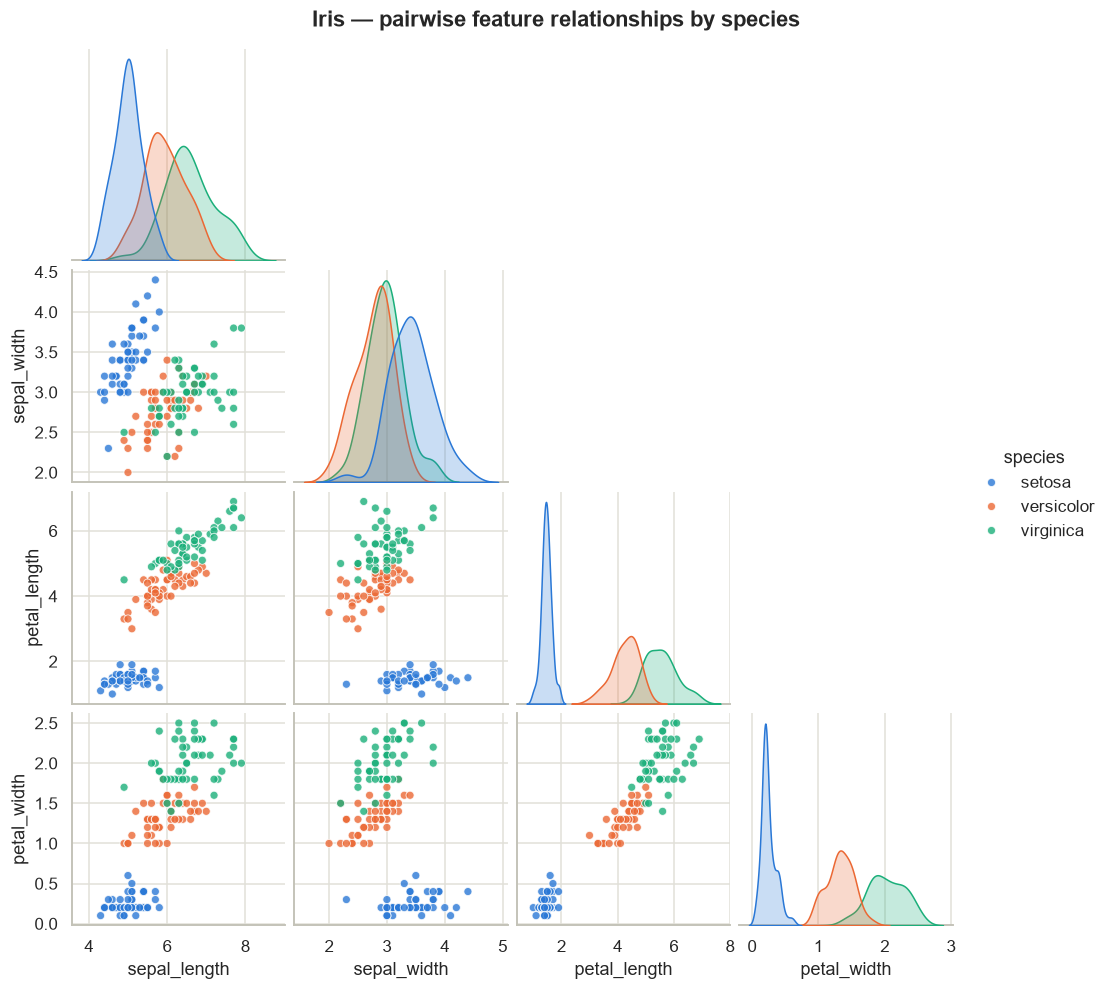

In [6]:
g = sns.pairplot(df, hue=TARGET_COLUMN, hue_order=CLASSES, palette=CLASS_COLORS,
                 diag_kind="kde", corner=True, height=2.2,
                 plot_kws={"s": 28, "alpha": 0.8, "edgecolor": "white", "linewidth": 0.6})
g.figure.suptitle("Iris — pairwise feature relationships by species", y=1.02, fontweight="bold")
g.savefig(FIGURES_DIR / "01_pairplot.png")
plt.show()

### 2.2 Feature distributions per class

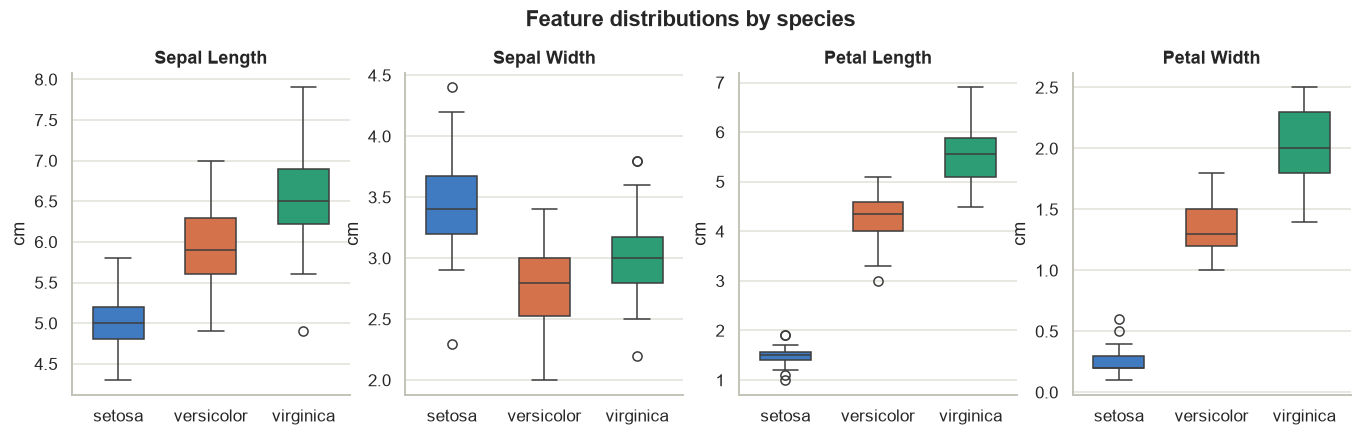

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, feat in zip(axes, FEATURES):
    sns.boxplot(data=df, x=TARGET_COLUMN, y=feat, hue=TARGET_COLUMN, order=CLASSES,
                hue_order=CLASSES, palette=CLASS_COLORS, legend=False, ax=ax, width=0.55,
                linewidth=1)
    ax.set_title(feat.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("cm")
fig.suptitle("Feature distributions by species", fontweight="bold", y=1.03)
fig.savefig(FIGURES_DIR / "02_feature_boxplots.png")
plt.show()

### 2.3 Feature correlation

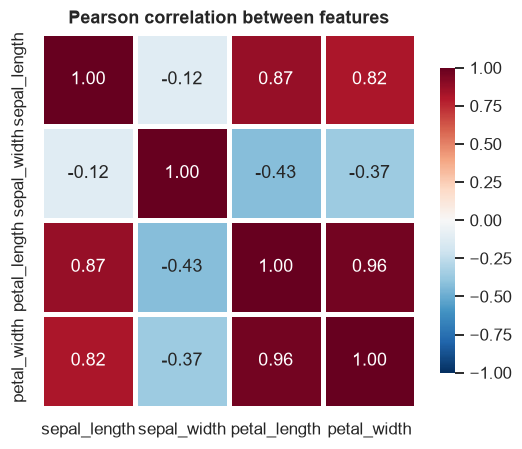

In [8]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation between features")
fig.savefig(FIGURES_DIR / "03_correlation_heatmap.png")
plt.show()

**EDA findings**
- **Setosa is linearly separable** from the other two species on petal length and petal width alone.
- **Versicolor and virginica overlap slightly**, so this is where any classification errors will happen.
- Petal length and petal width are highly correlated (r ≈ 0.96) and are the most discriminative features.
  Sepal width is the weakest feature.
- The features have different ranges (petal width ≈ 0.1–2.5 cm, sepal length ≈ 4–8 cm).
  Logistic Regression is sensitive to scale, which is why we standardise in step 4.

## 3. Train / test split (80/20, stratified)

In [9]:
X = df[FEATURES]
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).reindex(CLASSES)

Train: 120 samples | Test: 30 samples


,train,test
species,,
setosa,40,10
versicolor,40,10
virginica,40,10


Stratification keeps the 1:1:1 class ratio in both sets (40/40/40 train, 10/10/10 test).

## 4. Feature scaling (StandardScaler)

$z = (x - \mu_{train}) / \sigma_{train}$. The scaler is **fitted on the training set only** and then applied to
the test set, so no information from the test set leaks into training.

In [10]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

pd.DataFrame({
    "train mean (before)": X_train.mean(), "train std (before)": X_train.std(ddof=0),
    "train mean (after)": X_train_scaled.mean(), "train std (after)": X_train_scaled.std(ddof=0),
}).round(3)

,train mean (before),train std (before),train mean (after),train std (after)
sepal_length,5.842,0.837,-0.0,1.0
sepal_width,3.048,0.447,0.0,1.0
petal_length,3.770,1.761,0.0,1.0
petal_width,1.205,0.759,0.0,1.0


### 4.1 Save the processed data

The scaled train and test sets are saved to `data/processed/`, with the original row index and the label.
This records exactly which samples were used for training and testing, so the results can be reproduced
and later experiments (e.g. hyperparameter tuning) can reuse the same split.

In [11]:
train_processed = X_train_scaled.assign(**{TARGET_COLUMN: y_train})
test_processed = X_test_scaled.assign(**{TARGET_COLUMN: y_test})

train_processed.to_csv(PROCESSED_DATA_DIR / "train_scaled.csv", index_label="row_id", float_format="%.6f")
test_processed.to_csv(PROCESSED_DATA_DIR / "test_scaled.csv", index_label="row_id", float_format="%.6f")

print(f"Saved train_scaled.csv ({len(train_processed)} rows) and "
      f"test_scaled.csv ({len(test_processed)} rows) to {PROCESSED_DATA_DIR.relative_to(ROOT_DIR)}")

Saved train_scaled.csv (120 rows) and test_scaled.csv (30 rows) to data\processed


## 5. Model training & cross-validation

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{name:<20} trained | train accuracy = {model.score(X_train_scaled, y_train):.3f}")

Logistic Regression  trained | train accuracy = 0.958
Decision Tree        trained | train accuracy = 1.000


The test set has only 30 samples, so one misclassification moves accuracy by 3.3 points. To get a more
reliable estimate, we also run **stratified 5-fold cross-validation on the training set**. The scaler is put
inside a `Pipeline`, so it is re-fitted on each training fold and the folds stay leakage-free.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro"])
    cv_rows.append({
        "Model": name,
        "CV accuracy (mean)": scores["test_accuracy"].mean(),
        "CV accuracy (std)": scores["test_accuracy"].std(),
        "CV F1-macro (mean)": scores["test_f1_macro"].mean(),
        "CV F1-macro (std)": scores["test_f1_macro"].std(),
    })
cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(3)

,CV accuracy (mean),CV accuracy (std),CV F1-macro (mean),CV F1-macro (std)
Model,,,,
Logistic Regression,0.958,0.026,0.958,0.027
Decision Tree,0.950,0.017,0.950,0.017


## 6. Classification reports & benchmark metrics

In [14]:
predictions, probabilities = {}, {}
for name, model in models.items():
    predictions[name] = model.predict(X_test_scaled)
    probabilities[name] = model.predict_proba(X_test_scaled)
    print(f"{'=' * 60}\n{name}\n{'=' * 60}")
    print(classification_report(y_test, predictions[name], digits=3))

Logistic Regression


              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



In [15]:
rows = []
for name in models:
    y_pred, y_proba = predictions[name], probabilities[name]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted"),
        "ROC-AUC (OvR macro)": roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"),
    })
benchmark = pd.DataFrame(rows).set_index("Model")
benchmark.round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (OvR macro)
Model,,,,,,
Logistic Regression,0.933,0.933,0.933,0.933,0.933,0.997
Decision Tree,0.933,0.933,0.933,0.933,0.933,0.950


## 7. Confusion matrix heatmaps

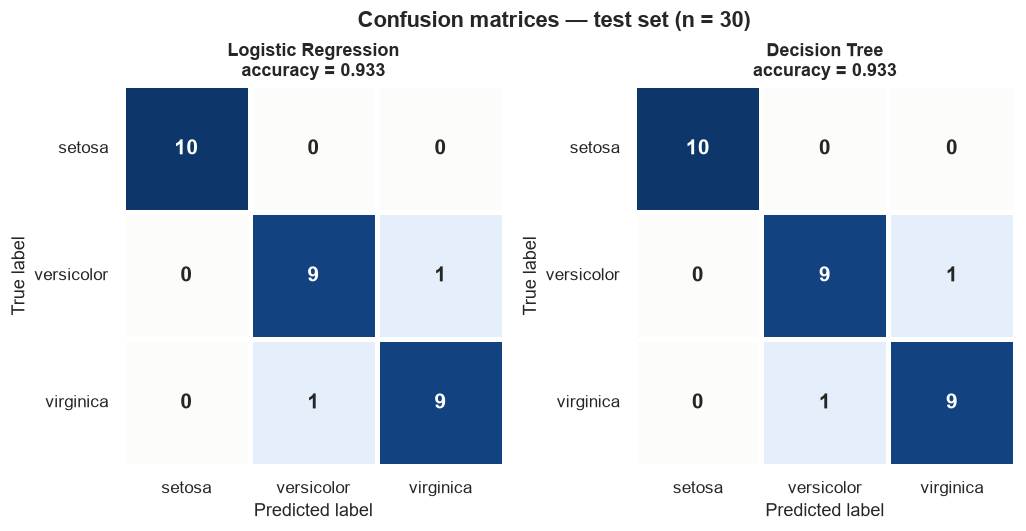

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name], labels=CLASSES)
    sns.heatmap(cm, annot=True, fmt="d", cmap=SEQ_CMAP, vmin=0, vmax=cm.sum(axis=1).max(),
                xticklabels=CLASSES, yticklabels=CLASSES, square=True, cbar=False,
                linewidths=2, linecolor="white", annot_kws={"size": 14, "weight": "bold"}, ax=ax)
    acc = accuracy_score(y_test, predictions[name])
    ax.set_title(f"{name}\naccuracy = {acc:.3f}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("Confusion matrices — test set (n = 30)", fontweight="bold", y=1.03)
fig.savefig(FIGURES_DIR / "04_confusion_matrices.png")
plt.show()

In [17]:
# Which test samples were misclassified?
mistakes = []
for name in models:
    wrong = y_test != predictions[name]
    for idx in y_test.index[wrong]:
        mistakes.append({"Model": name, "row": idx, **X_test.loc[idx].to_dict(),
                         "true": y_test[idx],
                         "predicted": predictions[name][y_test.index.get_loc(idx)]})
pd.DataFrame(mistakes) if mistakes else "No misclassifications on the test set."

,Model,row,sepal_length,sepal_width,petal_length,petal_width,true,predicted
0,Logistic Regression,134,6.1,2.6,5.6,1.4,virginica,versicolor
1,Logistic Regression,77,6.7,3.0,5.0,1.7,versicolor,virginica
2,Decision Tree,134,6.1,2.6,5.6,1.4,virginica,versicolor
3,Decision Tree,77,6.7,3.0,5.0,1.7,versicolor,virginica


## 8. ROC curves (one-vs-rest)

ROC curves are defined for binary problems. For 3 classes we use **one-vs-rest**: each species is treated
as "positive" against the other two. A fully grown Decision Tree outputs (almost) hard 0/1 probabilities,
so its ROC curve has only a few steps.

Each class has its own colour *and* line style. Versicolor and virginica can produce identical curves
(they are each other's only confusion), and the different line styles keep both visible when that happens.

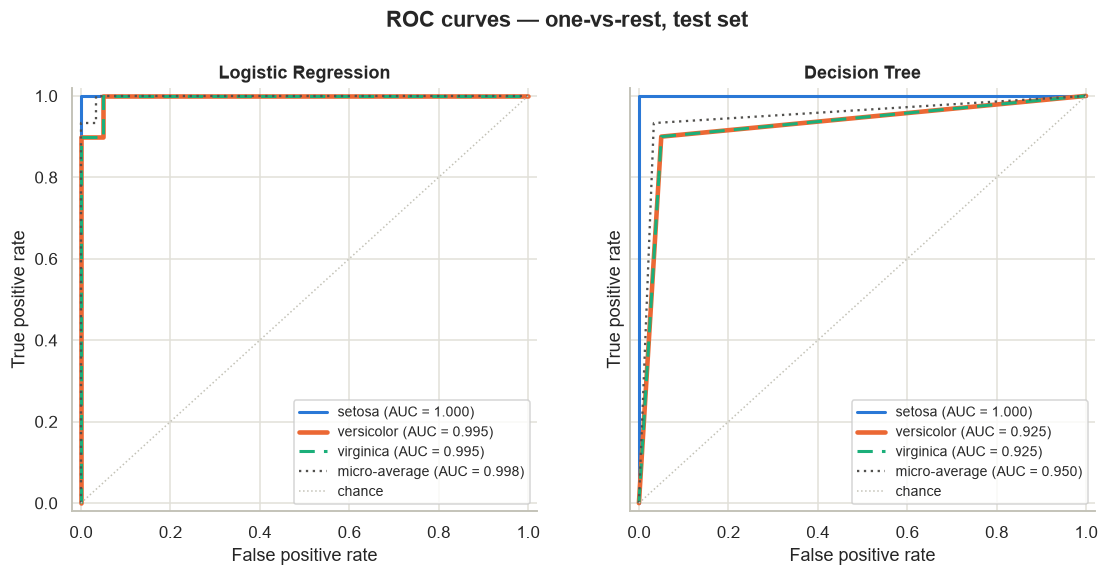

In [18]:
y_test_bin = label_binarize(y_test, classes=CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, name in zip(axes, models):
    y_proba = probabilities[name]
    for i, (cls, color, ls) in enumerate(zip(CLASSES, CLASS_COLORS, ["-", "-", (0, (5, 3))])):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        ax.plot(fpr, tpr, color=color, lw=3 if i == 1 else 2, ls=ls,
                label=f"{cls} (AUC = {auc(fpr, tpr):.3f})")
    fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_proba.ravel())
    ax.plot(fpr_micro, tpr_micro, color="#52514e", lw=1.5, ls=(0, (1, 2)),
            label=f"micro-average (AUC = {auc(fpr_micro, tpr_micro):.3f})")
    ax.plot([0, 1], [0, 1], color="#c3c2b7", lw=1, ls=":", label="chance")
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), xlabel="False positive rate",
           ylabel="True positive rate", title=name)
    ax.legend(loc="lower right", fontsize=9, frameon=True)
fig.suptitle("ROC curves — one-vs-rest, test set", fontweight="bold", y=1.02)
fig.savefig(FIGURES_DIR / "05_roc_curves.png")
plt.show()

## 9. Decision boundary visualisation

A decision boundary can only be drawn in 2-D, so we retrain both models on **two 2-D views** of the data:
1. **Petal length vs petal width** (scaled). These are the two most discriminative raw features.
2. **First two principal components (PCA)** of all four scaled features. Together they keep most of the variance.

The coloured regions show the class each model would predict at every point. Circles are training samples
and white-edged diamonds are test samples.

PCA explained variance: PC1 = 72.7%, PC2 = 23.1%, total = 95.7%


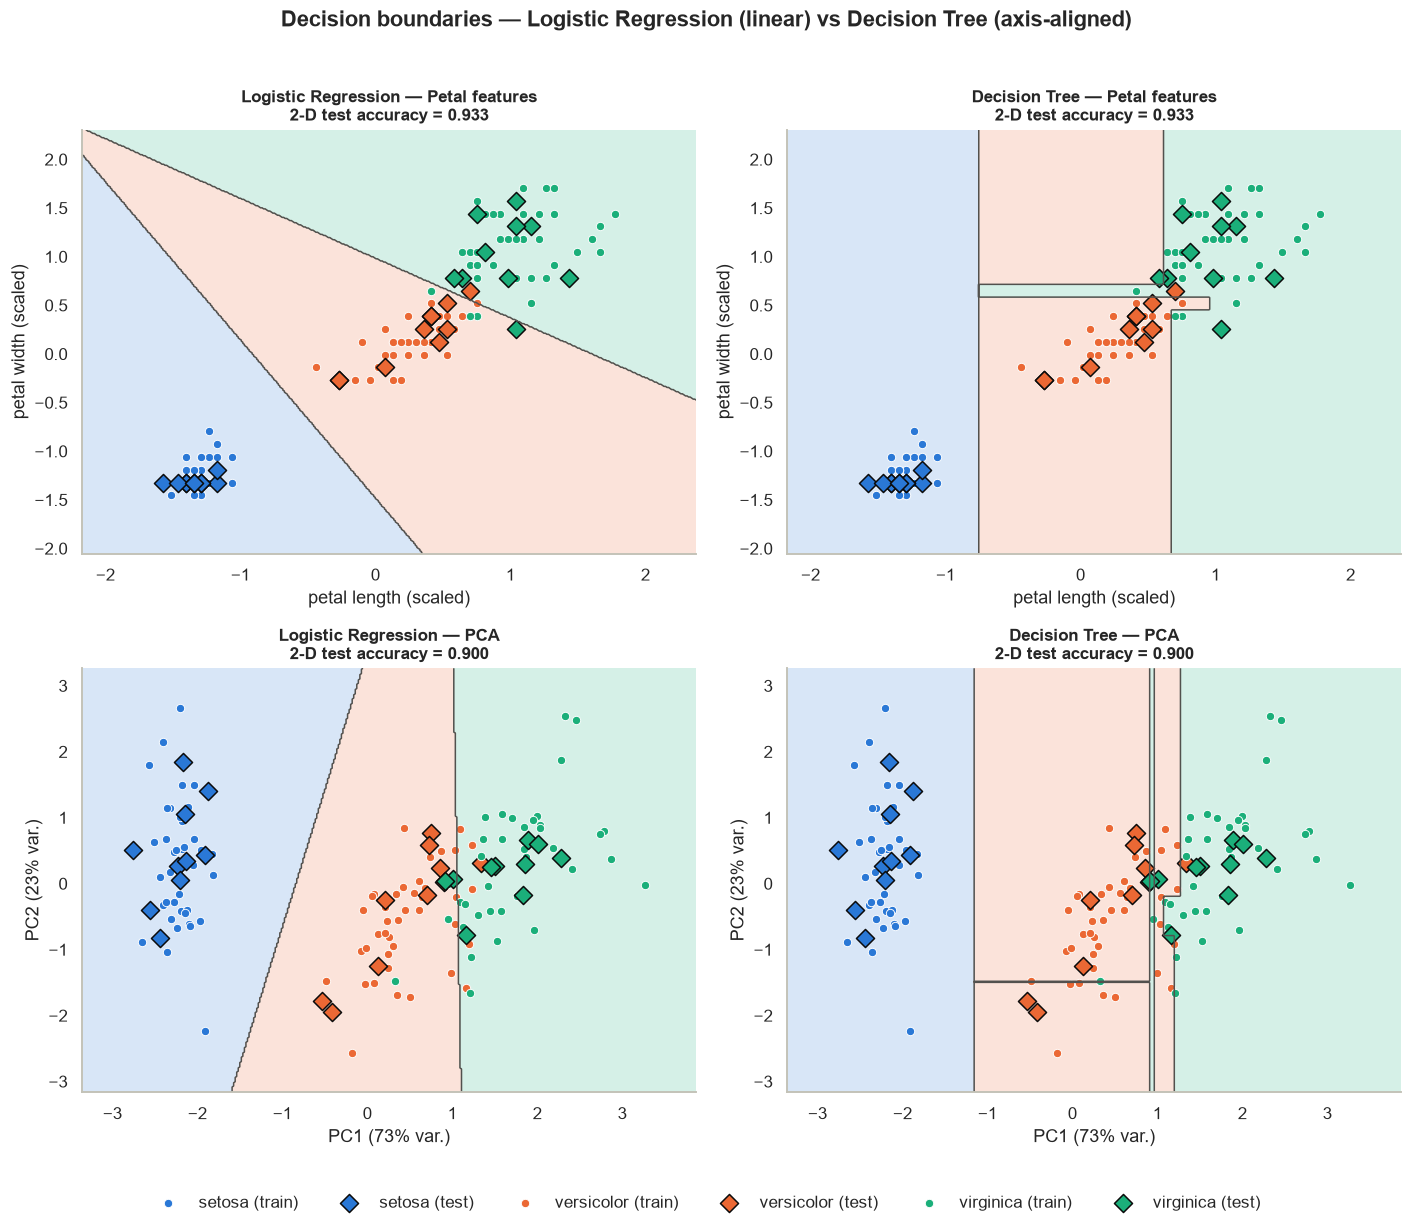

In [19]:
def plot_decision_boundary(ax, model, X2_train, y_train, X2_test, y_test, xlabel, ylabel, title):
    class_to_int = {c: i for i, c in enumerate(CLASSES)}
    pad = 0.6
    x_min, x_max = min(X2_train[:, 0].min(), X2_test[:, 0].min()) - pad, max(X2_train[:, 0].max(), X2_test[:, 0].max()) + pad
    y_min, y_max = min(X2_train[:, 1].min(), X2_test[:, 1].min()) - pad, max(X2_train[:, 1].max(), X2_test[:, 1].max()) + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = np.vectorize(class_to_int.get)(Z).reshape(xx.shape)

    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=CLASS_COLORS, alpha=0.18)
    ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors="#52514e", linewidths=1)
    for cls, color in zip(CLASSES, CLASS_COLORS):
        m_tr, m_te = (y_train == cls), (y_test == cls)
        ax.scatter(X2_train[m_tr, 0], X2_train[m_tr, 1], c=color, s=30, edgecolor="white",
                   linewidth=0.6, label=f"{cls} (train)")
        ax.scatter(X2_test[m_te, 0], X2_test[m_te, 1], c=color, s=70, marker="D",
                   edgecolor="#0b0b0b", linewidth=1, label=f"{cls} (test)")
    acc = accuracy_score(y_test, model.predict(X2_test))
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max), xlabel=xlabel, ylabel=ylabel)
    ax.set_title(f"{title}\n2-D test accuracy = {acc:.3f}", fontsize=11)
    ax.grid(False)

# View 1: petal features (already scaled)
petal = ["petal_length", "petal_width"]
Xp_train, Xp_test = X_train_scaled[petal].to_numpy(), X_test_scaled[petal].to_numpy()

# View 2: PCA on all 4 scaled features (fitted on train only)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xpca_train = pca.fit_transform(X_train_scaled)
Xpca_test = pca.transform(X_test_scaled)
ev = pca.explained_variance_ratio_
print(f"PCA explained variance: PC1 = {ev[0]:.1%}, PC2 = {ev[1]:.1%}, total = {ev.sum():.1%}")

views = [
    ("Petal features", Xp_train, Xp_test, "petal length (scaled)", "petal width (scaled)"),
    ("PCA", Xpca_train, Xpca_test, f"PC1 ({ev[0]:.0%} var.)", f"PC2 ({ev[1]:.0%} var.)"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for row, (view, Xtr2, Xte2, xl, yl) in enumerate(views):
    for col, (name, base_model) in enumerate(models.items()):
        model_2d = base_model.__class__(**base_model.get_params()).fit(Xtr2, y_train)
        plot_decision_boundary(axes[row, col], model_2d, Xtr2, y_train.to_numpy(),
                               Xte2, y_test.to_numpy(), xl, yl, f"{name} — {view}")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Decision boundaries — Logistic Regression (linear) vs Decision Tree (axis-aligned)",
             fontweight="bold", y=0.995)
fig.tight_layout(rect=(0, 0.04, 1, 0.98))
fig.savefig(FIGURES_DIR / "06_decision_boundaries.png")
plt.show()

**Reading the boundaries**
- **Logistic Regression** draws **straight (linear) boundaries**, because each class score is a weighted sum of the features.
- **Decision Tree** draws **axis-aligned, staircase-shaped regions**, because every split is a threshold on a single
  feature. In the overlap zone between versicolor and virginica it carves out small regions to fit individual
  training points. This is a sign of overfitting.

## 10. Performance summary & conclusions

In [20]:
summary = benchmark.join(cv_results[["CV accuracy (mean)", "CV accuracy (std)", "CV F1-macro (mean)"]])
summary.to_csv(REPORTS_DIR / "performance_summary.csv", float_format="%.4f")
summary.round(3)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (OvR macro),CV accuracy (mean),CV accuracy (std),CV F1-macro (mean)
Model,,,,,,,,,
Logistic Regression,0.933,0.933,0.933,0.933,0.933,0.997,0.958,0.026,0.958
Decision Tree,0.933,0.933,0.933,0.933,0.933,0.950,0.950,0.017,0.950


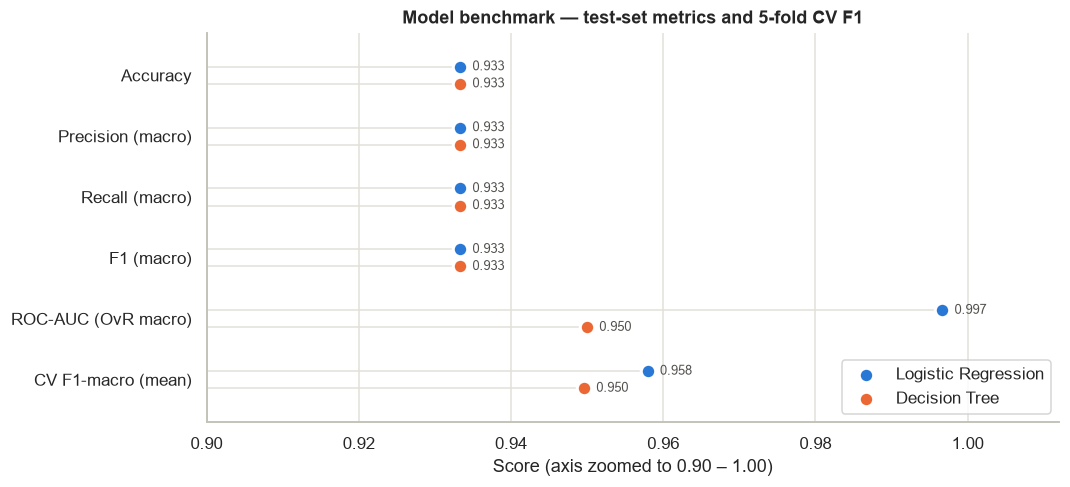

In [21]:
metrics_to_plot = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)",
                   "ROC-AUC (OvR macro)", "CV F1-macro (mean)"]

# Dot plot: the scores are all close to 1, so we zoom the axis.
# Bars would exaggerate the differences on a zoomed axis; dots don't.
fig, ax = plt.subplots(figsize=(10, 4.6))
y_pos = np.arange(len(metrics_to_plot))[::-1]
row_offset = {"Logistic Regression": 0.14, "Decision Tree": -0.14}  # so tied scores stay visible
for name in models:
    vals = summary.loc[name, metrics_to_plot].to_numpy(dtype=float)
    ys = y_pos + row_offset[name]
    ax.hlines(ys, 0.90, vals, color="#e1e0d9", lw=1, zorder=1)
    ax.scatter(vals, ys, s=90, color=MODEL_COLORS[name], edgecolor="white",
               linewidth=2, zorder=3, label=name)
    for v, yy in zip(vals, ys):
        ax.annotate(f"{v:.3f}", (v, yy), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color="#52514e")
ax.set_yticks(y_pos, metrics_to_plot)
ax.set_ylim(-0.7, len(metrics_to_plot) - 0.3)
ax.set_xlim(0.90, 1.012)
ax.set_xlabel("Score (axis zoomed to 0.90 – 1.00)")
ax.set_title("Model benchmark — test-set metrics and 5-fold CV F1")
ax.legend(loc="lower right", frameon=True)
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES_DIR / "07_performance_summary.png")
plt.show()

### Conclusions

| Model | Accuracy | Precision | Recall | F1 (macro) | ROC-AUC (OvR) | 5-fold CV F1 | Train acc. |
|---|---|---|---|---|---|---|---|
| **Logistic Regression** | 0.933 | 0.933 | 0.933 | 0.933 | **0.997** | **0.958 ± 0.027** | 0.958 |
| Decision Tree | 0.933 | 0.933 | 0.933 | 0.933 | 0.950 | 0.950 ± 0.017 | 1.000 |

**1. Both models reach 93.3 % test accuracy and make the same two mistakes.** Setosa is classified perfectly
by both models. The only errors are one versicolor predicted as virginica and one virginica predicted as
versicolor. Both samples lie in the region where the two species overlap, as the EDA predicted.

**2. Logistic Regression is the better model overall.** Its accuracy, precision, recall and F1 are identical
to the tree's, but:
- its **ROC-AUC is higher (0.997 vs 0.950)**. Its predicted probabilities rank samples almost perfectly,
  whereas the fully grown tree only outputs hard 0/1 probabilities;
- its **cross-validated F1 is slightly higher (0.958 vs 0.950)**;
- it **generalises more consistently**: train accuracy 0.958 vs test 0.933. The tree reaches 1.000 on the
  training set, so it has memorised it (overfitting), which also shows in its jagged decision boundaries.

**3. Scaling matters for Logistic Regression but not for the Decision Tree.** The tree splits on thresholds,
which are unaffected by rescaling. Logistic Regression uses regularised weights, which need features on the
same scale.

**Recommendation:** use **Logistic Regression** for this problem. It is simpler, more interpretable
(one coefficient per feature per class), better calibrated, and at least as accurate.

**Limitations & next steps**
- The test set is small (30 samples), so one error changes accuracy by 3.3 points. The CV differences
  between the models are within one standard deviation, so they should not be over-interpreted.
- Tune the tree with `GridSearchCV` (`max_depth`, `min_samples_leaf`) to reduce overfitting, and tune
  `C` for Logistic Regression.
- Benchmark more models (SVM, k-NN, Random Forest) and repeat the pipeline on the Wine dataset
  (13 features, where scaling has a much larger effect).